# Figure 4 — Sideband dynamics for different $g$ and $a$

Sideband probabilities $P_\ell(\zeta)$ for a phase-matched electron ($\delta_v=0$) on a $4\times4$ grid of
recoil parameters $a\in\{2000,4000,6000,8000\}$ (rows) and coupling strengths $g\in\{0.1,0.2,0.3,0.4\}$ (columns).
Overlays: nonrecoil maximum sideband $\ell=2g\zeta$ (white), classical bound $\ell=2\sqrt{ag}$ (green) and
predicted first revival $\zeta=\frac{\pi}{2}\sqrt{a/g}$ (cyan cross).

**Data files** (plain-text CSV, see `data/README.md`): `data/fig4/fig4_P_a{a}_g{g}.csv`, one sideband map
(rows $\ell$, columns $\zeta$) per panel, and `data/fig4/fig4_parameters.csv`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pinem_recoil as pr

DATA = Path("data") / "fig4"
FIGS = Path("figures")
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False

## Parameters

In [2]:
a_values = np.array([2000, 4000, 6000, 8000])
g_values = np.array([0.1, 0.2, 0.3, 0.4])
l_max = 130
zeta_max = 600
d_zeta = 1
d_phi = -d_zeta          # phase matching (delta_v = 0)

## Computation

In [3]:
files = {(a, g): DATA / f"fig4_P_a{a}_g{g:g}.csv" for a in a_values for g in g_values}
file_par = DATA / "fig4_parameters.csv"
if RECOMPUTE or not all(f.exists() for f in [*files.values(), file_par]):
    for (a, g), f in files.items():
        zeta, phi = pr.propagate_steps(a, g, l_max, d_zeta, d_phi, int(zeta_max / d_zeta))
        pr.save_map(f, np.abs(phi)**2, zeta, pr.sideband_axis(l_max), "zeta", "ell")
    pr.save_parameters(file_par, [
        ("a_values", " ".join(str(a) for a in a_values), "recoil parameters (rows of the figure)"),
        ("g_values", " ".join(f"{g:g}" for g in g_values), "coupling strengths (columns of the figure)"),
        ("l_max", l_max, "sideband truncation |l| <= l_max"),
        ("d_zeta", d_zeta, "propagation step"),
        ("d_phi", d_phi, "field-phase step per propagation step (phase matching)"),
    ])
    print("saved", len(files), "maps and", file_par)

saved 16 maps and data\fig4\fig4_parameters.csv


## Load data and plot

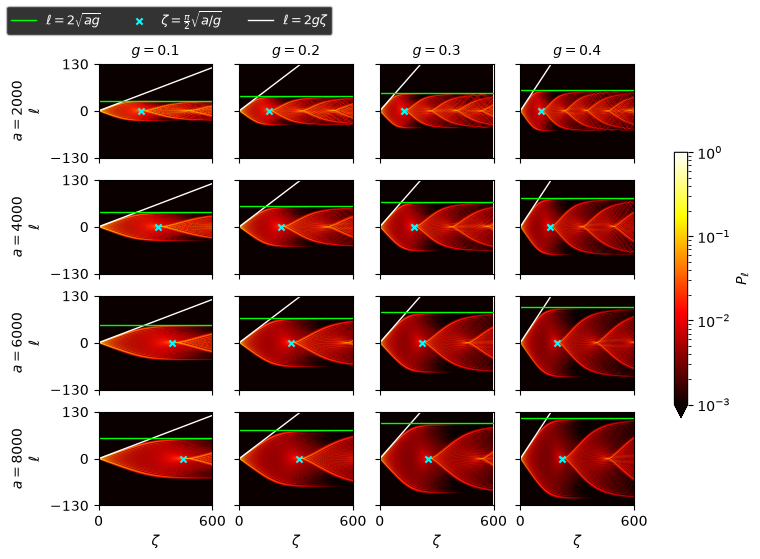

In [4]:
maps = {key: pr.load_map(f) for key, f in files.items()}     # (a, g) -> (zeta, ell, P)
zeta, ell, _ = maps[(a_values[0], g_values[0])]
cmap = plt.get_cmap("hot").copy()
cmap.set_under(cmap(0.0)); cmap.set_bad(cmap(0.0))
ext = [zeta[0] - 0.5, zeta[-1] + 0.5, ell[0] - 0.5, ell[-1] + 0.5]

fig, ax = plt.subplots(4, 4, figsize=(7.5, 5.5), sharex=True, sharey=True, constrained_layout=True)
for i, a in enumerate(a_values):
    for j, g in enumerate(g_values):
        im = ax[i, j].imshow(maps[(a, g)][2], aspect="auto", origin="lower", extent=ext,
                             norm=LogNorm(vmin=1e-3, vmax=1), cmap=cmap)
        z = zeta[2 * g * zeta < l_max]
        h1, = ax[i, j].plot(z, 2 * g * z, c="white", lw=1)
        h2 = ax[i, j].axhline(2 * np.sqrt(a * g), c="lime", lw=1)
        h3 = ax[i, j].scatter([np.pi / 2 * np.sqrt(a / g)], [0], s=20, c="cyan", marker="x")
        ax[i, j].set_ylim(ell[0], ell[-1])
    ax[i, 0].set_ylabel(rf"$a={a:.0f}$" + "\n" + r"$\ell$")
for j, g in enumerate(g_values):
    ax[0, j].set_title(rf"$g={g:.1f}$", fontsize=10)
    ax[3, j].set_xlabel(r"$\zeta$")
ax[3, 0].set_xticks([0, zeta_max])
ax[3, 0].set_yticks([-l_max, 0, l_max])
fig.legend([h2, h3, h1], [r"$\ell=2\sqrt{ag}$", r"$\zeta=\frac{\pi}{2}\sqrt{a/g}$", r"$\ell=2g\zeta$"],
           loc="outside upper left", ncol=3, facecolor="k", labelcolor="w", fontsize=9)
cb = fig.colorbar(im, ax=ax, extend="min", shrink=0.6)
cb.set_label(r"$P_\ell$")
fig.savefig(FIGS / "fig4.png", dpi=200)
fig.savefig(FIGS / "fig4.pdf")
plt.show()